In [58]:
import time
import warnings
import numpy as np
import scipy.sparse as sp
import scipy.linalg as la
import matplotlib.pyplot as plt

from scipy.interpolate import RBFInterpolator
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

print("All imports successful.")
warnings.filterwarnings("ignore")

All imports successful.


In [59]:
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

# Parameters
n_el, T, dt, Pe = 1000, 0.5, 1e-6, 100
x0, w0 = 0.2, 0.01

h, n = 1 / n_el, n_el - 1
x = np.linspace(0, 1, n_el + 1)[1:-1]

def tri(a, b, c):
    return sp.diags([a, b, c], [-1, 0, 1], shape=(n, n), format="csc")

M = h / 6 * tri(1, 4, 1)
K = 1 / h * tri(-1, 2, -1)
C = 0.5 * tri(-1, 0, 1)
M_solve = spla.splu(M).solve

assert dt <= h**2 * Pe / 6
assert Pe * h / 2 <= 1

u = np.exp(-((x - x0) / w0)**2)
n_steps = round(T / dt)

start = time.perf_counter()

for _ in range(n_steps):
    C_u = C @ sp.diags(u)
    A_u = K / Pe + C_u
    u -= dt * M_solve(A_u @ u)

fom_time = time.perf_counter() - start
print(f"FOM runtime (Pe={Pe}): {fom_time:.3f} s")

FOM runtime (Pe=100): 182.547 s


In [80]:
M = sp.load_npz("M.npz").toarray()
K = sp.load_npz("K.npz").toarray()
C = sp.load_npz("C.npz").toarray()

d100 = np.load("snapshots/trajectory_40.npz")
d1000 = np.load("snapshots/trajectory_80.npz")

S100, S1000 = d100["S"], d1000["S"]
x = d100["x"]

print("M:", M.shape)
print("K:", K.shape)
print("C:", C.shape)
print("S100:", S100.shape)
print("S1000:", S1000.shape)
print("x:", x.shape)
print("Available fields:", d100.files)

M: (999, 999)
K: (999, 999)
C: (999, 999)
S100: (999, 1001)
S1000: (999, 1001)
x: (999,)
Available fields: ['S', 't', 'x', 'Pe']


# Reduced-Order Modeling of a Parametric Advection–Diffusion Problem

We compare intrusive and non-intrusive reduced-order models for a one-dimensional finite-element problem.

The methods are tested for two parameter values, \(Pe=10\) and \(Pe=1000\), representing different balances between diffusion and advection.

The reference solution is available as a collection of FOM snapshots. We construct POD bases and compare the resulting reduced models in terms of accuracy and computational cost.

**Methods**
- Proper Orthogonal Decomposition (POD)
- Intrusive ROM with Discrete Empirical Interpolation (DEIM)
- Non-intrusive POD-RBF, POD-NN and POD-GPR
- Projection errors, computational timings and convergence

In [ ]:
N_SNAPSHOTS = 900
energy_target = 0.99999
dt, T, T_eval = 1e-6, 0.5, 0.4

In [82]:
def get_times(d, S):
    t = d["t"] if "t" in d.files else np.linspace(0, T, S.shape[1])
    t = np.asarray(t).ravel()
    if len(t) != S.shape[1]:
        raise ValueError("Number of snapshot times does not match snapshots.")
    return t


def subsample(S, t, n, t_eval):
    n = min(n, S.shape[1])
    idx = np.linspace(0, S.shape[1] - 1, n, dtype=int)
    i_eval = np.argmin(np.abs(t - t_eval))
    if i_eval not in idx:
        idx[np.argmin(np.abs(t[idx] - t_eval))] = i_eval
    idx = np.unique(idx)
    return S[:, idx], t[idx]

t100, t1000 = get_times(d100, S100), get_times(d1000, S1000)

S100, t100 = subsample(S100, t100, N_SNAPSHOTS, T_eval)
S1000, t1000 = subsample(S1000, t1000, N_SNAPSHOTS, T_eval)

i100 = np.argmin(abs(t100 - T_eval))
i1000 = np.argmin(abs(t1000 - T_eval))

F100, F1000 = S100[:, i100], S1000[:, i1000]

print("Pe = 100:", S100.shape, "evaluation time:", t100[i100])
print("Pe = 1000:", S1000.shape, "evaluation time:", t1000[i1000])

Pe = 100: (999, 900) evaluation time: 0.39999999999999997
Pe = 1000: (999, 900) evaluation time: 0.39999999999999997


## 1. Proper Orthogonal Decomposition

POD constructs a low-dimensional basis that captures the dominant energetic structures in the snapshot ensemble.

For the snapshot matrix $S=[u_1,\ldots,u_{n_s}]$, we solve the snapshot correlation eigenproblem

$
S^\top M S\,w_i=\lambda_i w_i.
$

The corresponding spatial modes are

$
\phi_i=\frac{S w_i}{\sqrt{\lambda_i}}.
$

The modes are orthonormal in the mass-matrix inner product,$\Phi^\top M\Phi=I$.

We retain the smallest number of modes that reaches the prescribed cumulative energy threshold.

In [83]:

def err_M(F, u):
    d = F - u
    return np.sqrt(d @ M @ d)


def pod(S):
    lam, W = la.eigh(S.T @ M @ S)
    lam, W = lam[::-1], W[:, ::-1]
    p = lam > 1e-14 * lam[0]
    lam, W = lam[p], W[:, p]
    e = np.cumsum(lam / lam.sum())
    N = np.searchsorted(e, energy_target) + 1
    return S @ W[:, :N] / np.sqrt(lam[:N]), N, lam, e


def full_pod(S):
    lam, W = la.eigh(S.T @ M @ S)
    lam, W = lam[::-1], W[:, ::-1]
    p = lam > 1e-14 * lam[0]
    return S @ W[:, p] / np.sqrt(lam[p])

# =====================================================================
# POD
# =====================================================================
start = time.perf_counter()
Z100, N100, lam100, e100 = pod(S100)
pod_off100 = time.perf_counter() - start

start = time.perf_counter()
Z1000, N1000, lam1000, e1000 = pod(S1000)
pod_off1000 = time.perf_counter() - start

print(f"Pe = 100: N = {N100}, retained energy = {100*e100[N100-1]:.4f}%")
print(f"Pe = 1000: N = {N1000}, retained energy = {100*e1000[N1000-1]:.4f}%")

Pe = 100: N = 5, retained energy = 99.9057%
Pe = 1000: N = 18, retained energy = 99.9264%


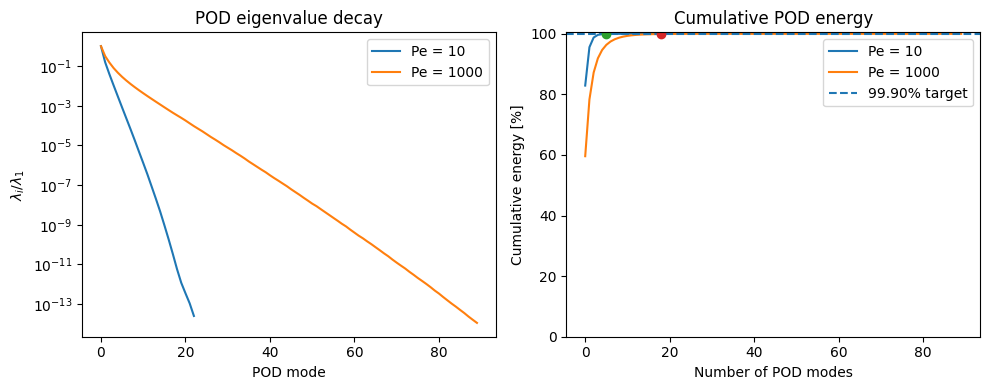

In [84]:
# =====================================================================
# POD eigenvalues and cumulative energy
# =====================================================================
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].semilogy(lam100 / lam100[0], label="Pe = 10")
axs[0].semilogy(lam1000 / lam1000[0], label="Pe = 1000")
axs[0].set(xlabel="POD mode", ylabel=r"$\lambda_i/\lambda_1$",
           title="POD eigenvalue decay")
axs[0].legend()

axs[1].plot(100*e100, label="Pe = 10")
axs[1].plot(100*e1000, label="Pe = 1000")
axs[1].axhline(100*energy_target, ls="--",
               label=f"{100*energy_target:.2f}% target")
axs[1].plot(N100, 100*e100[N100-1], "o")
axs[1].plot(N1000, 100*e1000[N1000-1], "o")
axs[1].set(xlabel="Number of POD modes", ylabel="Cumulative energy [%]",
           title="Cumulative POD energy", ylim=(0, 100.5))
axs[1].legend()
plt.tight_layout()
plt.show()

### Intrusive ROM: POD-DEIM

The intrusive reduced-order model (ROM) is obtained by projecting the governing equations onto a low-dimensional POD basis. For a nonlinear problem, the reduced nonlinear term can still be expensive to evaluate because it depends on the full-order state. The **Discrete Empirical Interpolation Method (DEIM)** approximates this term using a small number of selected degrees of freedom, reducing the online computational cost.

The resulting method combines **POD for dimensionality reduction** and **DEIM for hyper-reduction**.

### Intrusive ROM: POD-DEIM

The finite-element discretization of the governing equation leads to the nonlinear system

$$
\mathbf M \frac{d\mathbf u}{dt}
+\frac{1}{\mathrm{Pe}}\mathbf K\mathbf u
+\mathbf C(\mathbf u)\mathbf u
=\mathbf 0,
$$

where $\mathbf M$ and $\mathbf K$ are the mass and diffusion matrices, respectively, and $\mathbf C(\mathbf u)\mathbf u$ represents the nonlinear advection term.

We approximate the solution using a POD basis $\mathbf Z\in\mathbb R^{n_h\times N}$:

$$
\mathbf u(t)\approx\mathbf Z\mathbf a(t),
$$

where \(N\ll n_h\). Projecting the governing equations onto the POD space gives the reduced system

$$
\underbrace{\mathbf Z^\top\mathbf M\mathbf Z}_{\mathbf M_N}
\frac{d\mathbf a}{dt}
+\frac{1}{\mathrm{Pe}}
\underbrace{\mathbf Z^\top\mathbf K\mathbf Z}_{\mathbf K_N}
\mathbf a
+\mathbf Z^\top\mathbf C(\mathbf Z\mathbf a)\mathbf Z\mathbf a
=\mathbf 0.
$$

For a mass-orthonormal POD basis, $\mathbf M_N=\mathbf I$.

The nonlinear term still requires evaluating the full-order state and nonlinear operator. **DEIM** approximates this term using a small number \(m\) of selected degrees of freedom, reducing the computational cost of the online stage.

In [85]:
# =====================================================================
# DEIM
# =====================================================================
m_max, f_tol = 1000, 1e-15


def pod_nl(Fn):
    U, s, _ = la.svd(Fn, full_matrices=False)
    m = min(m_max, int(np.sum(s > f_tol * s[0])))
    return U[:, :m], s


def deim_points(G):
    p = [int(np.argmax(np.abs(G[:, 0])))]
    for l in range(1, G.shape[1]):
        c = la.solve(G[p, :l], G[p, l])
        r = G[:, l] - G[:, :l] @ c
        p.append(int(np.argmax(np.abs(r))))
    return np.array(p)


def deim_setup(Z, G, p):
    B = la.solve(G[p, :].T, (Z.T @ G).T).T
    idx = np.flatnonzero(np.any(C[p, :] != 0, axis=0))
    return B, C[np.ix_(p, idx)], Z[idx, :]


start = time.perf_counter()
Fn100 = C @ S100**2
Gf100, sv100 = pod_nl(Fn100)
pf100 = deim_points(Gf100)
deim_data_off100 = time.perf_counter() - start

start = time.perf_counter()
Fn1000 = C @ S1000**2
Gf1000, sv1000 = pod_nl(Fn1000)
pf1000 = deim_points(Gf1000)
deim_data_off1000 = time.perf_counter() - start

m100, m1000 = min(4*N100, Gf100.shape[1]), min(4*N1000, Gf1000.shape[1])
print(f"DEIM: Pe = 100: m = {m100}, Pe = 1000: m = {m1000}")


def rom_deim(Z, S, Pe, G, p, T_end=T_eval):
    start = time.perf_counter()
    B, C_P, Z_S = deim_setup(Z, G, p)
    K_N = Z.T @ K @ Z
    setup_time = time.perf_counter() - start

    a = Z.T @ M @ S[:, 0]
    n_steps = round(T_end / dt)

    start = time.perf_counter()
    for _ in range(n_steps):
        u_S = Z_S @ a
        a -= dt * (K_N @ a / Pe + B @ (C_P @ (u_S**2)))
    online_time = time.perf_counter() - start

    return Z @ a, setup_time, online_time


u100d, deim_setup100, time100d = rom_deim(
    Z100, S100, 100, Gf100[:, :m100], pf100[:m100]
)
u1000d, deim_setup1000, time1000d = rom_deim(
    Z1000, S1000, 1000, Gf1000[:, :m1000], pf1000[:m1000]
)

deim_off100 = deim_data_off100 + deim_setup100
deim_off1000 = deim_data_off1000 + deim_setup1000

err100d, err1000d = err_M(F100, u100d), err_M(F1000, u1000d)
print(f"DEIM-ROM at t = {T_eval}:\n"
      f"Pe = 100  err = {err100d:.3e} "
      f"(offline = {deim_off100:.2f} s, online = {time100d:.2f} s)\n"
      f"Pe = 1000 err = {err1000d:.3e} "
      f"(offline = {deim_off1000:.2f} s, online = {time1000d:.2f} s)")

DEIM: Pe = 100: m = 20, Pe = 1000: m = 72
DEIM-ROM at t = 0.4:
Pe = 100  err = 3.939e-04 (offline = 0.30 s, online = 3.37 s)
Pe = 1000 err = 6.679e-04 (offline = 0.38 s, online = 3.46 s)


### Non-intrusive ROMs: learning the dynamics

Instead of projecting the governing equations, we learn the time evolution of the POD coefficients directly from the available snapshots.

Given the snapshot matrix $\mathbf S=[\mathbf u(t_1),\ldots,\mathbf u(t_{N_s})]$, we first compute the POD basis $\mathbf Z$ and project the snapshots onto it:

$$
\mathbf A=\mathbf Z^\top\mathbf M\mathbf S,
$$

where each column of $\mathbf A$ contains the reduced coefficients at a given time.

We then treat time as the input parameter and the POD coefficients as the outputs. The available time samples are split into training and test sets, withholding one snapshot to evaluate the prediction at an unseen time.

We compare three regression methods:

1. **Radial basis functions (RBF):** interpolate the reduced coefficients using radial basis functions centered at the training points.
2. **Neural network (NN):** train a multilayer perceptron to map time to POD coefficients. Input times and output coefficients are standardized before training, and the network parameters are optimized by minimizing the prediction error.
3. **Gaussian process regression (GPR):** learn a probabilistic mapping from time to POD coefficients using a Matérn covariance kernel. Kernel hyperparameters are optimized during training.

Once trained, each model predicts the coefficients $\widehat{\mathbf a}(t)$ at a new time. The corresponding full-order approximation is reconstructed as

$$
\widehat{\mathbf u}(t)=\mathbf Z\widehat{\mathbf a}(t).
$$

**Key difference:** these methods learn the solution from data without requiring the governing equations during online prediction. Their accuracy and computational cost depend on the training data and the chosen regression method.

In [86]:
# =====================================================================
# NON-INTRUSIVE ROMs: time is the parameter
# =====================================================================
def split(S, t, i_test):
    tr = np.arange(S.shape[1]) != i_test
    return S[:, tr], t[tr]


def coeffs(Z, S):
    return Z.T @ M @ S

How do we train and use the regression models?

All three functions receive:

t_tr: the training times, with shape $(N_{\mathrm{tr}},)$.

A_tr: the corresponding POD coefficients, with shape $(N,N_{\mathrm{tr}})$, where $N$ is the number of POD modes.

The objective is to learn the mapping

$$
t \longmapsto \mathbf a(t)\in\mathbb R^N.
$$

In [87]:
def fit_rbf(t_tr, A_tr, kernel="thin_plate_spline"):
    f = RBFInterpolator(t_tr[:, None], A_tr.T, kernel=kernel)
    return lambda t: f(np.atleast_1d(t)[:, None]).T

1. Radial basis function interpolation (RBF)

We approximate each coefficient using radial basis functions centered at the training times:

$$
\widehat{\mathbf a}(t)
=\sum_{j=1}^{N_{\mathrm{tr}}}
\boldsymbol{\omega}_j\phi(|t-t_j|).
$$

The weights $\boldsymbol{\omega}_j\in\mathbb R^N$ are obtained by enforcing interpolation at the training points. This leads to a linear system,

$$
\mathbf\Phi\mathbf\Omega=\mathbf A_{\mathrm{tr}}^\top,
\qquad
\Phi_{ij}=\phi(|t_i-t_j|).
$$

For the thin-plate spline, $\phi(r)=r^2\log r$, with $\phi(0)=0$; the standard RBF interpolant also includes a polynomial term, handled internally by SciPy. Once the weights are computed, prediction requires only evaluating the interpolant.

Main choice: the RBF kernel, which determines the shape of the interpolant.

In [88]:


def fit_nn(t_tr, A_tr, seed=0):
    sx, sy = StandardScaler(), StandardScaler()
    X = sx.fit_transform(t_tr[:, None])
    Y = sy.fit_transform(A_tr.T)

    net = MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="tanh",
        solver="adam",
        learning_rate_init=1e-3,
        max_iter=5000,
        tol=1e-6,
        early_stopping=False,
        random_state=seed,
        verbose=True,
    )
    net.fit(X, Y)

    def pred(t):
        t = np.atleast_1d(t)
        y = net.predict(sx.transform(t[:, None]))
        return sy.inverse_transform(y.reshape(len(t), -1)).T

    return pred

    return pred


We approximate the coefficient map using a neural network,

$$
\widehat{\mathbf a}(t)=
NN(t;\boldsymbol\theta),
$$

where $\boldsymbol\theta$ collects all weights and biases. Training consists of minimizing the empirical loss

$$
\boldsymbol\theta^*=
\arg\min_{\boldsymbol\theta}
\frac{1}{N_{\mathrm{tr}}}
\sum_{i=1}^{N_{\mathrm{tr}}}
\left|
NN(t_i;\boldsymbol\theta)-\mathbf a_i
\right|_2^2.
$$

The optimization is performed here using L-BFGS.

Main hyperparameters in our implementation:

-Architecture: two hidden layers with 64 neurons each.

-Activation: hyperbolic tangent (tanh).

-Optimizer: L-BFGS.

Maximum iterations and tolerance: 5000 and (10^{-12}), respectively.

The inputs and outputs are standardized before training and transformed back after prediction.



In [89]:

def fit_gp(mu_train, A_train):
    sx, sy = StandardScaler(), StandardScaler()
    X = sx.fit_transform(mu_train[:, None])
    Y = sy.fit_transform(A_train.T)

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(length_scale=0.3, length_scale_bounds="fixed", nu=2.5)
        + WhiteKernel(noise_level=1e-6, noise_level_bounds="fixed")
    )

    model = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
    )
    model.fit(X, Y)

    def predict(mu):
        mu = np.atleast_1d(mu)
        Yp = model.predict(sx.transform(mu[:, None]))
        return sy.inverse_transform(Yp.reshape(len(mu), -1)).T

    return predict

Instead of directly parameterizing a function, GPR models the unknown coefficient map as a Gaussian process:

$$
a_k(t)\sim GP \big(m(t),k(t,t')\big).
$$

For training times $\mathbf t$, let $\mathbf K$ be the kernel matrix, with $K_{ij}=k(t_i,t_j)$. For a new time $t_*$, the predictive mean is

$$
\widehat{a}_k(t_*) =
\mathbf{k}_*^\top
\left(\mathbf{K}+\sigma_n^2\mathbf{I}\right)^{-1}
\mathbf{y}_k
$$

where $\mathbf k_=[k(t_,t_i)]_i$, $\mathbf y_k$ contains the training values of coefficient $k$, and $\sigma_n^2$ is the noise variance. In practice, the inverse is computed through a linear solve.

The kernel defines the smoothness and correlation structure of the function. In our implementation, we use a Matérn kernel with $\nu=2.5$, multiplied by a constant amplitude, plus a white-noise term.

Main hyperparameters: the kernel length scale, signal amplitude, and noise level. They are optimized from the training data by maximizing the log marginal likelihood.

The prediction formula above is applied to each POD coefficient. Our implementation returns the predictive mean, without evaluating the uncertainty.

In [90]:
fitters = {
    "POD-RBF": fit_rbf,
    "POD-NN": fit_nn,
    "POD-GPR": fit_gp,
}


In [91]:

def nonintrusive(S, t, i_test, N, F):
    start = time.perf_counter()
    S_tr, t_tr = split(S, t, i_test)
    V = full_pod(S_tr)[:, :N]
    A_tr = coeffs(V, S_tr)
    basis_time = time.perf_counter() - start

    out, models = {}, {}
    for name, fit in fitters.items():
        start = time.perf_counter()
        pred = fit(t_tr, A_tr)
        fit_time = time.perf_counter() - start
        models[name] = pred

        start = time.perf_counter()
        a = pred(t[i_test])[:, 0]
        u = V @ a
        online_time = time.perf_counter() - start

        out[name] = (err_M(F, u), basis_time + fit_time, online_time, u)

    start = time.perf_counter()
    P = V @ (V.T @ M @ F)
    proj_time = time.perf_counter() - start

    return out, err_M(F, P), basis_time, proj_time, models

In [92]:
res100, proj100, ni_basis100, proj_time100, models100 = nonintrusive(
    S100, t100, i100, N100, F100
)
res1000, proj1000, ni_basis1000, proj_time1000, models1000 = nonintrusive(
    S1000, t1000, i1000, N1000, F1000
)

Iteration 1, loss = 0.41273973
Iteration 2, loss = 0.32878022
Iteration 3, loss = 0.31676311
Iteration 4, loss = 0.32228466
Iteration 5, loss = 0.31476345
Iteration 6, loss = 0.30867683
Iteration 7, loss = 0.30650298
Iteration 8, loss = 0.30488179
Iteration 9, loss = 0.30253958
Iteration 10, loss = 0.29980979
Iteration 11, loss = 0.29750795
Iteration 12, loss = 0.29461222
Iteration 13, loss = 0.29081170
Iteration 14, loss = 0.28752872
Iteration 15, loss = 0.28467375
Iteration 16, loss = 0.28046089
Iteration 17, loss = 0.27636288
Iteration 18, loss = 0.27282616
Iteration 19, loss = 0.26887656
Iteration 20, loss = 0.26480754
Iteration 21, loss = 0.26107659
Iteration 22, loss = 0.25690791
Iteration 23, loss = 0.25367201
Iteration 24, loss = 0.25007183
Iteration 25, loss = 0.24657664
Iteration 26, loss = 0.24371537
Iteration 27, loss = 0.24063672
Iteration 28, loss = 0.23761309
Iteration 29, loss = 0.23441246
Iteration 30, loss = 0.23190891
Iteration 31, loss = 0.23009824
Iteration 32, los

In [93]:
for lab, res, proj, N in (
    ("Pe = 100", res100, proj100, N100),
    ("Pe = 1000", res1000, proj1000, N1000),
):
    print(f"{lab} (N = {N}): projection error = {proj:.3e}")
    for k, v in res.items():
        print(f"  {k:<12}: error = {v[0]:.3e}, "
              f"offline = {v[1]:.3f} s, online = {v[2]*1e3:.3f} ms")

Pe = 100 (N = 5): projection error = 2.943e-04
  POD-RBF     : error = 2.943e-04, offline = 0.180 s, online = 0.173 ms
  POD-NN      : error = 3.298e-04, offline = 1.560 s, online = 0.392 ms
  POD-GPR     : error = 2.943e-04, offline = 0.209 s, online = 0.931 ms
Pe = 1000 (N = 18): projection error = 5.787e-04
  POD-RBF     : error = 5.787e-04, offline = 0.165 s, online = 0.135 ms
  POD-NN      : error = 6.612e-04, offline = 7.383 s, online = 0.344 ms
  POD-GPR     : error = 5.787e-04, offline = 0.181 s, online = 0.636 ms


In [94]:

# =====================================================================
# TIMING SUMMARY
# =====================================================================
def report_timings(title, data, fom_time):
    print(f"\n{title}")
    print("-" * 82)
    print(f"{'Method':<20} {'Offline [s]':>14} {'Online [ms]':>14} {'Speed-up':>14}")
    for name, (off, on) in data.items():
        speedup = fom_time / on if on > 0 else float("nan")
        print(f"{name:<20} {off:>14.4f} {on*1e3:>14.4f} {speedup:>13.2f}x")


report_timings("TIMINGS: Pe = 10", {
    "POD": (pod_off100, 0.0),
    "DEIM-ROM": (deim_off100, time100d),
    **{k: (v[1], v[2]) for k, v in res100.items()},
    "Projection": (ni_basis100, proj_time100),
}, fom_time)

report_timings("TIMINGS: Pe = 1000", {
    "POD": (pod_off1000, 0.0),
    "DEIM-ROM": (deim_off1000, time1000d),
    **{k: (v[1], v[2]) for k, v in res1000.items()},
    "Projection": (ni_basis1000, proj_time1000),
}, fom_time)



TIMINGS: Pe = 10
----------------------------------------------------------------------------------
Method                  Offline [s]    Online [ms]       Speed-up
POD                          0.2419         0.0000           nanx
DEIM-ROM                     0.2957      3371.9756         54.14x
POD-RBF                      0.1798         0.1733    1053160.53x
POD-NN                       1.5603         0.3918     465979.45x
POD-GPR                      0.2086         0.9308     196111.93x
Projection                   0.1655         1.1677     156335.20x

TIMINGS: Pe = 1000
----------------------------------------------------------------------------------
Method                  Offline [s]    Online [ms]       Speed-up
POD                          0.1529         0.0000           nanx
DEIM-ROM                     0.3754      3457.4466         52.80x
POD-RBF                      0.1650         0.1346    1356393.33x
POD-NN                       7.3831         0.3436     531240.38x
POD-

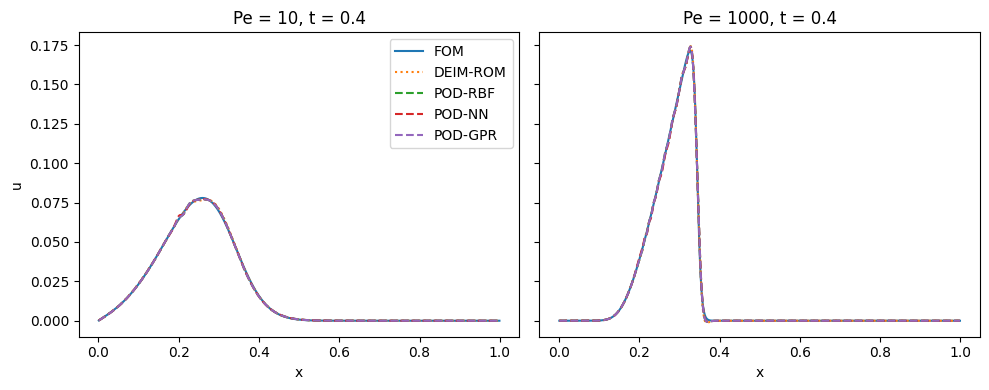

In [95]:
# =====================================================================
# FOM vs DEIM-ROM vs non-intrusive ROM
# =====================================================================
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, F, ud, res, ttl in (
    (axs[0], F100, u100d, res100, "Pe = 10"),
    (axs[1], F1000, u1000d, res1000, "Pe = 1000"),
):
    ax.plot(x, F, label="FOM")
    ax.plot(x, ud, ":", label="DEIM-ROM")
    for k, v in res.items():
        ax.plot(x, v[3], "--", label=k)
    ax.set(title=f"{ttl}, t = {T_eval}", xlabel="x")

axs[0].set_ylabel("u")
axs[0].legend()
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

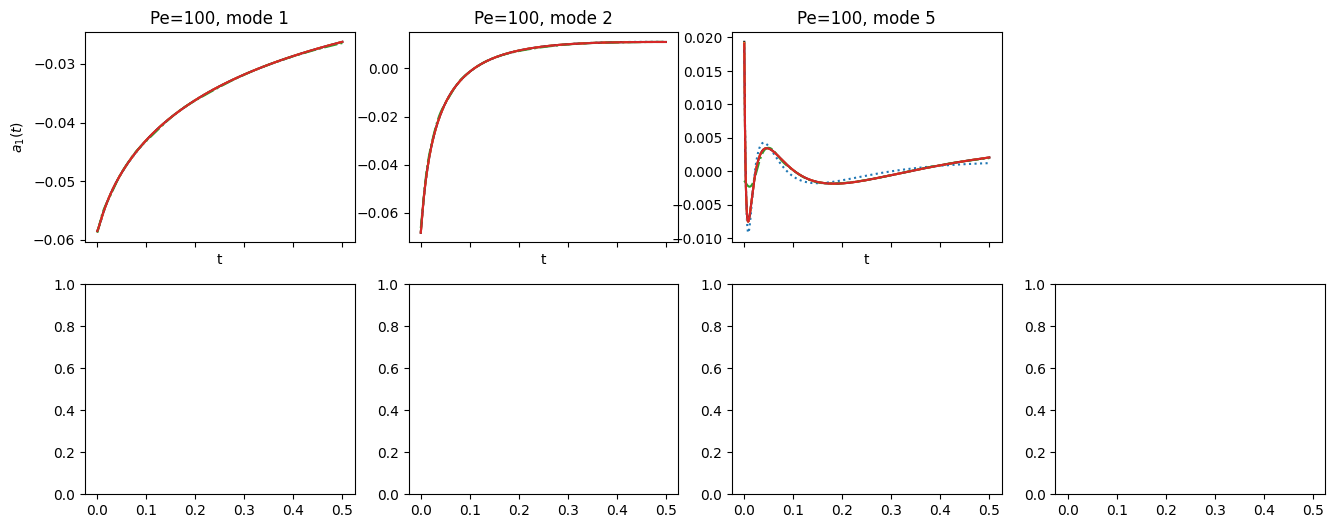

In [96]:
# =====================================================================
# POD coefficient dynamics: projection vs intrusive and non-intrusive ROMs
# =====================================================================
modes_plot = [1, 2, 5, 10]

def deim_coefficients(Z, S, Pe, G, p, t_out):
    """Integrate DEIM-ROM and return POD coefficients at t_out."""
    B, C_P, Z_S = deim_setup(Z, G, p)
    K_N = Z.T @ K @ Z
    a = Z.T @ M @ S[:, 0]

    steps = np.rint(t_out / dt).astype(int)
    save = {step: j for j, step in enumerate(steps)}
    A = np.zeros((Z.shape[1], len(t_out)))
    A[:, 0] = a

    for n in range(1, steps[-1] + 1):
        u_S = Z_S @ a
        a -= dt * (K_N @ a / Pe + B @ (C_P @ (u_S**2)))
        if n in save:
            A[:, save[n]] = a

    return A


def coefficient_dynamics(S, t, i_test, N, Pe, Gf, pf, models):
    S_tr, t_tr = split(S, t, i_test)
    V = full_pod(S_tr)[:, :N]
    A_proj = V.T @ M @ S

    A_pred = {name: model(t) for name, model in models.items()}

    m = min(4*N, Gf.shape[1])
    A_deim = deim_coefficients(V, S, Pe, Gf[:, :m], pf[:m], t)
    return A_proj, A_deim, A_pred


fig, axs = plt.subplots(2, len(modes_plot), figsize=(4*len(modes_plot), 6),
                        sharex=True)

for row, (Pe, S, t, i_test, N, Gf, pf, models) in enumerate((
    (100, S100, t100, i100, N100, Gf100, pf100, models100),
    (1000, S1000, t1000, i1000, N1000, Gf1000, pf1000, models1000),
)):
    A_proj, A_deim, A_pred = coefficient_dynamics(
        S, t, i_test, N, Pe, Gf, pf, models
    )

    for j, mode in enumerate(modes_plot):
        if mode > N:
            axs[row, j].set_visible(False)
            continue

        k = mode - 1
        ax = axs[row, j]
        ax.plot(t, A_proj[k], "k-", label="FOM / POD projection")
        ax.plot(t, A_deim[k], ":", label="DEIM-ROM")
        ax.plot(t, A_pred["POD-RBF"][k], "--", label="POD-RBF")
        ax.plot(t, A_pred["POD-NN"][k], "-.", label="POD-NN")
        ax.plot(t, A_pred["POD-GPR"][k], "-", label="POD-GPR")
        ax.set_title(f"Pe={Pe}, mode {mode}")
        ax.set_xlabel("t")
        if j == 0:
            ax.set_ylabel(rf"$a_{{{mode}}}(t)$")

axs[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [77]:
# =====================================================================
# Convergence study vs number of POD modes
# =====================================================================
Z100f, Z1000f = full_pod(S100), full_pod(S1000)
Ns = [1, 10, 20, 40, 80]
keys = list(fitters)
E = {(pe, k): [] for pe in (100, 1000) for k in keys}
err100ds, err1000ds, p100s, p1000s, pt100s, pt1000s = [], [], [], [], [], []

for N in Ns:
    print(f"N = {N}")
    V100, V1000 = Z100f[:, :N], Z1000f[:, :N]

    P100 = V100 @ (V100.T @ M @ F100)
    P1000 = V1000 @ (V1000.T @ M @ F1000)
    p100s.append(err_M(F100, P100))
    p1000s.append(err_M(F1000, P1000))

    mm100 = min(8*N, Gf100.shape[1])
    mm1000 = min(8*N, Gf1000.shape[1])

    u100d_, _, _ = rom_deim(V100, S100, 100, Gf100[:, :mm100], pf100[:mm100])
    u1000d_, _, _ = rom_deim(
        V1000, S1000, 1000, Gf1000[:, :mm1000], pf1000[:mm1000]
    )
    err100ds.append(err_M(F100, u100d_))
    err1000ds.append(err_M(F1000, u1000d_))

    r100, pt100, _, _, _ = nonintrusive(S100, t100, i100, N, F100)
    r1000, pt1000, _, _, _ = nonintrusive(S1000, t1000, i1000, N, F1000)
    pt100s.append(pt100)
    pt1000s.append(pt1000)

    for k in keys:
        E[(100, k)].append(r100[k][0])
        E[(1000, k)].append(r1000[k][0])


fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, pe, ed, ps, pts in (
    (axs[0], 100, err100ds, p100s, pt100s),
    (axs[1], 1000, err1000ds, p1000s, pt1000s),
):
    ax.semilogy(Ns, ed, "o:", label="DEIM-ROM (intrusive)")
    for k, mk in zip(keys, "sd^"):
        ax.semilogy(Ns, E[(pe, k)], mk + "-", label=k)
    ax.semilogy(Ns, ps, "k--", label="Projection (all snapshots)")
    ax.semilogy(Ns, pts, "k-.", label="Projection (train basis)")
    ax.set(title=f"Pe = {pe}", xlabel="Number of POD modes (m = 8N for DEIM)")

axs[0].set_ylabel(f"Error at t = {T_eval}")
axs[0].legend()
plt.tight_layout()
plt.show()

N = 1
Iteration 1, loss = 0.29399427
Iteration 2, loss = 0.06249876
Iteration 3, loss = 0.07692411
Iteration 4, loss = 0.07834026
Iteration 5, loss = 0.04989436
Iteration 6, loss = 0.04820782
Iteration 7, loss = 0.05080828
Iteration 8, loss = 0.04544087
Iteration 9, loss = 0.04253798
Iteration 10, loss = 0.04236548
Iteration 11, loss = 0.04029143
Iteration 12, loss = 0.03932234
Iteration 13, loss = 0.03838589
Iteration 14, loss = 0.03699020
Iteration 15, loss = 0.03557630
Iteration 16, loss = 0.03443787
Iteration 17, loss = 0.03304337
Iteration 18, loss = 0.03171258
Iteration 19, loss = 0.03021561
Iteration 20, loss = 0.02901100
Iteration 21, loss = 0.02715927
Iteration 22, loss = 0.02561693
Iteration 23, loss = 0.02422955
Iteration 24, loss = 0.02247887
Iteration 25, loss = 0.02082023
Iteration 26, loss = 0.01928127
Iteration 27, loss = 0.01768530
Iteration 28, loss = 0.01626086
Iteration 29, loss = 0.01479375
Iteration 30, loss = 0.01357392
Iteration 31, loss = 0.01242856
Iteration 3

KeyboardInterrupt: 